In [33]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [34]:
data = pd.read_csv('/content/diabetes.csv')

In [35]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


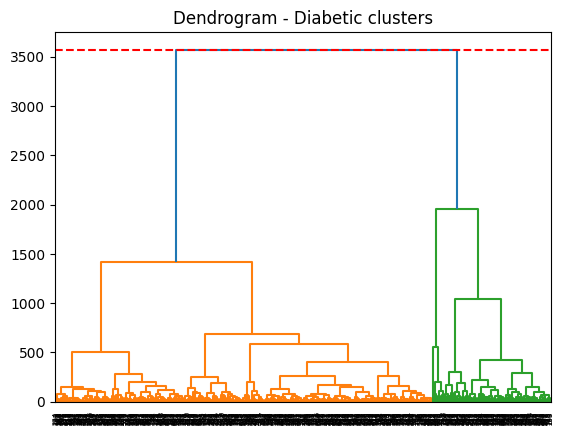

In [36]:
import scipy.cluster.hierarchy as sch
linkage_matrix = sch.linkage(data, method='ward')
dendrogram = sch.dendrogram(linkage_matrix)
plt.title('Dendrogram - Diabetic clusters')
from scipy.cluster.hierarchy import fcluster
plt.axhline(y=linkage_matrix[-(2 - 1), 2], color='r', linestyle='--')

plt.show()

# Get the cluster assignments for k = 2
clusters = fcluster(linkage_matrix, t=2, criterion='maxclust')

In [37]:
cluster_sizes = pd.Series(clusters).value_counts().sort_index()

print("Size of each cluster:")
print(cluster_sizes)

Size of each cluster:
1    585
2    183
Name: count, dtype: int64


In [38]:
country_data = pd.read_csv('/content/3.01. Country clusters.csv')

In [39]:
country_data.head()

,Country,Latitude,Longitude,Language
0,USA,44.97,-103.77,English
1,Canada,62.40,-96.80,English
2,France,46.75,2.40,French
3,UK,54.01,-2.53,English
4,Germany,51.15,10.40,German


In [40]:
sliced_country_data = country_data.iloc[:,1:3]

In [41]:
sliced_country_data.head()

,Latitude,Longitude
0,44.97,-103.77
1,62.40,-96.80
2,46.75,2.40
3,54.01,-2.53
4,51.15,10.40


Text(0.5, 1.0, 'Dendrogram - Country clusters')

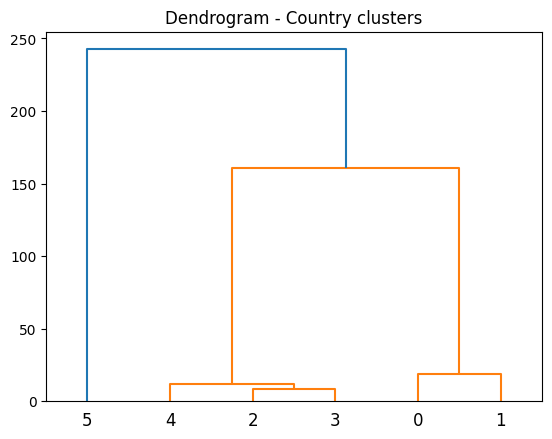

In [42]:
country_dendrogram = sch.dendrogram(sch.linkage(sliced_country_data, method='ward'))
plt.title('Dendrogram - Country clusters')